# C2 from diffusion trajectories

Can the **path** the counterfactual takes predict whether C0 was right? This restarts the old
fingerprint experiment (`code/cf/cf_fingerprint_cv.py`, features from
`code/cf/cf_extract_diverse_features.py`) on the new graded diffusion counterfactuals.

| | old fingerprint | this notebook |
|---|---|---|
| CFs per image | 15 cells: 5 regions (4 masked + general) x t_start 5/10/20 | 3 levels (low/mid/high soft target), unmasked, tau=150 |
| trajectory | C0 prob at every step (4-19 points) | C0 prob every 5 steps, t=145 to 1 (30 points) |
| rows | 5,431-image grid | the frozen 20k subset (`diffusion_hml_sub20k`) |
| folds | own StratifiedGroupKFold | **the same folds as the diffusion C2 arm** (read from its pairing files) |

The features are the old `traj_features` unchanged (the pixel/diff-map and `align_*` features are
left out: this is the trajectory only). One feature block per level, pivoted wide as `<feat>__L<level>`.

Models and hyper-parameters are the old script's (LR / RF / MLP / HGB, median impute + missing
indicators for everything except HGB). Feature sets: `prob_only`, `fingerprint`, `both`.
Baseline: threshold MSP.

In [6]:
import json, os, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from tqdm.auto import tqdm

from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, str(Path.cwd() / "code"))
from c2_msp import msp_score

DISEASE     = "atelectasis"      # atelectasis / cardiomegaly / consolidation have folds; effusion is still generating
RESULTS_DIR = Path(os.environ.get("THESIS_RESULTS", "/work3/s251710/thesis_results"))
CF_DIR      = RESULTS_DIR / "CF_levels" / DISEASE
FOLD_DIR    = RESULTS_DIR / "C2_final_folds" / DISEASE / "diffusion_hml_sub20k" / "cf_3"
ARM_DIR     = RESULTS_DIR / "C2_final_results" / DISEASE / "diffusion_hml_sub20k" / "cf_3" / "attributes"
C2_CSV      = RESULTS_DIR / "C2_final" / DISEASE / "c2_data.csv"

N_FOLDS, RANDOM_SEED, HGB_MAX_ITER, POLY_DEG = 5, 42, 300, 3
LEVELS = {1: "low", 2: "mid", 3: "high"}

## 1. Data: manifest, labels, folds

In [7]:
lv = json.loads((CF_DIR / "levels.json").read_text())
THR = lv["threshold"]

# one row per image; sharded runs (effusion) have one manifest per shard
man = pd.concat([pd.read_csv(p) for p in sorted(CF_DIR.glob("manifest*.csv"))])
img = man.drop_duplicates("path")[["path", "key", "cell", "orig_pred", "direction"]]

# correctness + the C0 prob B1 uses come from c2_data.csv, not the manifest
lab = pd.read_csv(C2_CSV, usecols=["path", "patient_id", "prob", "correct"]).rename(columns={"prob": "orig_prob"})
img = img.merge(lab, on="path", how="inner")

# fold = the fold in which the image is a TEST row, from the diffusion arm's pairing files
fold_of = pd.concat([pd.read_parquet(FOLD_DIR / f"pairing_fold_{k}.parquet", columns=["fold", "split", "path"])
                     .query("split == 'test'") for k in range(N_FOLDS)])
img = img.merge(fold_of[["path", "fold"]], on="path", how="inner").set_index("path")

print(f"{DISEASE}: {len(img):,} images | {img.patient_id.nunique():,} patients | "
      f"correct rate {img.correct.mean():.3f} | threshold {THR:.4f}")
print(img.cell.value_counts().to_dict())
print(img.groupby("fold").size().to_dict())

atelectasis: 20,000 images | 12,511 patients | correct rate 0.592 | threshold 0.1886
{'TN': 9103, 'FP': 7233, 'TP': 2741, 'FN': 923}
{0: 3964, 1: 4038, 2: 4048, 3: 4004, 4: 3946}


## 2. Load trajectories

In [8]:
def load_trajs(keys):
    # (n_images, 3 levels, n_steps) of C0 prob, in denoising order (t high -> 1)
    out, t_ref = [], None
    for k in tqdm(keys, desc="trajectories"):
        z = np.load(CF_DIR / "trajectory" / f"{k}.npz")
        arrs = [z[f"level_{l}"] for l in LEVELS]
        if t_ref is None:
            t_ref = arrs[0][:, 0]
        out.append(np.stack([a[:, 1] for a in arrs]))
    return np.stack(out).astype(np.float32), t_ref

cache = CF_DIR / "trajectory_probs.npz"
if cache.exists():
    z = np.load(cache, allow_pickle=True)
    P, T_STEPS, cached_paths = z["P"], z["t"], z["paths"]
    assert list(cached_paths) == list(img.index), "cache out of sync with the image table; delete it"
else:
    P, T_STEPS = load_trajs(img["key"])
    np.savez(cache, P=P, t=T_STEPS, paths=np.array(img.index))
print(P.shape, "t:", T_STEPS[:3], "...", T_STEPS[-2:])

(20000, 3, 30) t: [145. 140. 135.] ... [5. 1.]


## 3. Look at them

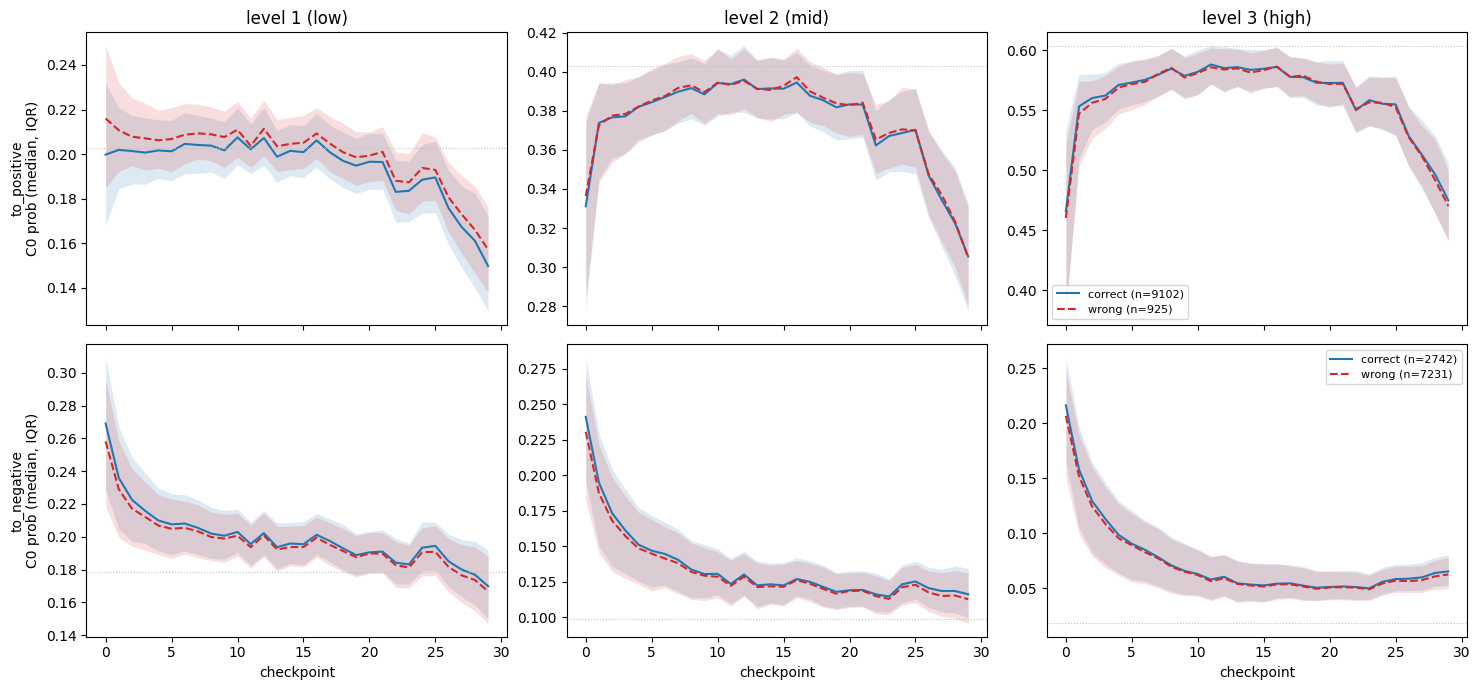

In [27]:
# rows = direction, cols = level; every panel gets its own y-scale, since the levels sit at
# very different probabilities (to_positive low ~0.2 vs high ~0.9; to_negative all near 0)
DIRS = ["to_positive", "to_negative"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
x = np.arange(P.shape[2])
flat = img.reset_index()
for ri, d in enumerate(DIRS):
    sub = flat[flat.direction == d]
    for li in range(3):
        ax = axes[ri, li]
        for c, col, ls in ((1, "C0", "-"), (0, "C3", "--")):
            idx = sub.index[sub.correct == c]
            q25, q50, q75 = np.percentile(P[idx, li], [25, 50, 75], axis=0)
            ax.plot(x, q50, ls, color=col, label=f"{'correct' if c else 'wrong'} (n={len(idx)})")
            ax.fill_between(x, q25, q75, color=col, alpha=0.15, lw=0)
        ax.axhline(lv[d][li], color="#BFBFBF", lw=0.8, ls=":")   # the level's soft target
        if ri == 0:
            ax.set_title(f"level {li + 1} ({LEVELS[li + 1]})")
        if ri == 1:
            ax.set_xlabel("checkpoint")
    axes[ri, 0].set_ylabel(f"{d}\nC0 prob (median, IQR)")
    axes[ri, -1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4. Trajectory features

`traj_features` is the old function, verbatim apart from dropping `n_steps` (constant here).
`pred` is C0's original prediction, so `sign` points in the intended direction of travel.

In [10]:
def vec_summary(v, prefix):
    if len(v) == 0:
        return {f"{prefix}_{k}": np.nan for k in ("mean", "max", "min", "std", "absmax", "argmax_pos")}
    return {
        f"{prefix}_mean": float(v.mean()), f"{prefix}_max": float(v.max()),
        f"{prefix}_min": float(v.min()),   f"{prefix}_std": float(v.std()),
        f"{prefix}_absmax": float(np.abs(v).max()),
        f"{prefix}_argmax_pos": float(np.argmax(np.abs(v)) / max(len(v) - 1, 1)),
    }


def traj_features(probs, pred, thr):
    sign = -1.0 if pred else 1.0
    d, a = np.diff(probs), np.diff(np.diff(probs))
    ds   = d * sign
    tot  = np.abs(d).sum()
    net  = probs[-1] - probs[0]

    crossed      = (probs >= thr) != bool(pred)
    first_cross  = int(np.argmax(crossed)) + 1 if crossed.any() else np.nan
    ends_flipped = bool(crossed[-1])
    if ends_flipped:
        run = len(crossed) if crossed.all() else int(np.argmin(crossed[::-1]))
        steps_to_flip = len(crossed) - run + 1
    else:
        steps_to_flip = np.nan

    xx = np.linspace(0, 1, len(probs))
    c  = np.polyfit(xx, probs, POLY_DEG)
    resid = float(np.sqrt(np.mean((probs - np.polyval(c, xx)) ** 2)))

    out = {
        "traj_start": float(probs[0]), "traj_end": float(probs[-1]),
        "first_cross_step": first_cross, "ever_crossed": int(crossed.any()),
        "steps_to_flip": steps_to_flip, "ends_flipped": int(ends_flipped),
        "n_crossings": int((np.diff(crossed.astype(int)) != 0).sum()),
        "mono_ratio":  float(ds[ds > 0].sum() / tot) if tot > 0 else np.nan,
        "backtrack":   float(np.abs(ds[ds < 0]).sum()),
        "n_reversals": int((np.diff(np.sign(d)) != 0).sum()),
        "reversal_rate": float((np.diff(np.sign(d)) != 0).sum() / max(len(d) - 1, 1)),
        "tv_ratio":    float(tot / abs(net)) if abs(net) > 0.02 else np.nan,
        "spearman":    float(spearmanr(np.arange(len(probs)), probs).correlation * sign),
        "net_delta":   float(net * sign),
        "total_variation": float(tot),
        "p0_level": float(c[3]), "p1_slope": float(c[2]),
        "p2_curvature": float(c[1]), "p3_sshape": float(c[0]),
        "poly_resid": resid,
    }
    out.update(vec_summary(d, "vel"))
    out.update(vec_summary(a, "acc"))
    return out


rows = []
for i, pred in enumerate(tqdm(img["orig_pred"].values, desc="features")):
    r = {}
    for li in range(3):
        r.update({f"{k}__L{li + 1}": v for k, v in traj_features(P[i, li], pred, THR).items()})
    rows.append(r)
F = pd.DataFrame(rows, index=img.index)

F = F.loc[:, F.nunique(dropna=False) > 1]          # drop constant columns
FP_COLS = list(F.columns)
X_all = img[["patient_id", "fold", "correct", "orig_prob"]].join(F)
print(f"{len(FP_COLS)} fingerprint columns | NaN rate {F.isna().values.mean():.2%}")

features:   0%|          | 0/20000 [00:00<?, ?it/s]

96 fingerprint columns | NaN rate 1.00%


## 5. Models

LR / RF / HGB are `cf_fingerprint_cv.py`'s. The MLP keeps the same 64-32-16 ReLU body but takes two
things from `c2_mlp_balanced.py`:

- **class-balanced BCE** (`pos_weight = n_neg / n_pos`); sklearn's `MLPClassifier` has no class weight
- **early stopping on val AUC** (patience 10) over a **20% patient-grouped val split** of the training
  fold, restoring the best epoch; sklearn stops on accuracy over a random 5%

No MSP skip, PCA, dropout or seed averaging.

In [11]:
import torch
import torch.nn as nn
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import GroupShuffleSplit

DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class BalancedMLP(BaseEstimator, ClassifierMixin):
    # 64-32-16 ReLU, Adam, class-balanced BCE, early stopping on the AUC of a patient-grouped val split

    def __init__(self, hidden=(64, 32, 16), lr=1e-3, weight_decay=1e-4, batch_size=200,
                 max_epochs=200, patience=10, val_frac=0.20, random_state=RANDOM_SEED):
        self.hidden, self.lr, self.weight_decay, self.batch_size = hidden, lr, weight_decay, batch_size
        self.max_epochs, self.patience, self.val_frac, self.random_state = max_epochs, patience, val_frac, random_state

    def fit(self, X, y, groups):
        fit_idx, val_idx = next(GroupShuffleSplit(n_splits=1, test_size=self.val_frac,
                                                  random_state=self.random_state).split(X, y, groups))
        torch.manual_seed(self.random_state)
        T = lambda a: torch.tensor(a, dtype=torch.float32, device=DEV)
        Xf, yf, Xv, yv = T(X[fit_idx]), T(y[fit_idx]), T(X[val_idx]), y[val_idx]

        self.net_ = self._build(X.shape[1]).to(DEV)
        opt = torch.optim.Adam(self.net_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        pos_weight = (len(fit_idx) - y[fit_idx].sum()) / y[fit_idx].sum()
        loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight, device=DEV))

        best, bad, state = -1.0, 0, None
        g = torch.Generator().manual_seed(self.random_state)
        for ep in range(self.max_epochs):
            self.net_.train()
            for idx in torch.randperm(len(yf), generator=g).split(self.batch_size):
                idx = idx.to(DEV)
                opt.zero_grad()
                loss_fn(self.net_(Xf[idx]).squeeze(1), yf[idx]).backward()
                opt.step()
            self.net_.eval()
            with torch.no_grad():
                auc = roc_auc_score(yv, self.net_(Xv).squeeze(1).cpu().numpy())
            if auc > best:
                best, bad, self.best_epoch_ = auc, 0, ep + 1
                state = {k: v.clone() for k, v in self.net_.state_dict().items()}
            else:
                bad += 1
                if bad >= self.patience:
                    break
        self.net_.load_state_dict(state)
        self.classes_ = np.array([0, 1])
        return self

    def _build(self, n_in):
        layers, w = [], n_in
        for h in self.hidden:
            layers += [nn.Linear(w, h), nn.ReLU()]
            w = h
        return nn.Sequential(*layers, nn.Linear(w, 1))

    def predict_proba(self, X):
        self.net_.eval()
        with torch.no_grad():
            p = torch.sigmoid(self.net_(torch.tensor(X, dtype=torch.float32, device=DEV)).squeeze(1))
        p = p.cpu().numpy().astype(np.float64)
        return np.column_stack([1 - p, p])


class _SeqNet(nn.Module):
    # first n_ch*n_steps inputs are the trajectories (level-major), the rest are scalars
    def __init__(self, n_in, n_ch, n_steps):
        super().__init__()
        self.n_ch, self.n_steps = n_ch, n_steps
        self.conv = nn.Sequential(nn.Conv1d(n_ch, 16, 5, padding=2), nn.ReLU(),
                                  nn.Conv1d(16, 32, 5, padding=2), nn.ReLU())
        n_sc = n_in - n_ch * n_steps
        self.head = nn.Sequential(nn.Linear(64 + n_sc, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        k = self.n_ch * self.n_steps
        h = self.conv(x[:, :k].reshape(-1, self.n_ch, self.n_steps))
        return self.head(torch.cat([h.mean(2), h.amax(2), x[:, k:]], 1))


class SeqCNN(BalancedMLP):
    # same training as BalancedMLP (balanced BCE, val-AUC early stopping), 1D-CNN body
    def __init__(self, n_ch=3, n_steps=30, **kw):
        super().__init__(**kw)
        self.n_ch, self.n_steps = n_ch, n_steps

    def _build(self, n_in):
        return _SeqNet(n_in, self.n_ch, self.n_steps)


NEEDS_GROUPS = {"MLP", "CNN"}      # models that carve a patient-grouped val split out of train


def make_model(model_type):
    impute = SimpleImputer(strategy="median", add_indicator=True)
    if model_type == "LR":
        return Pipeline([("impute", impute), ("scale", StandardScaler()),
                         ("clf", LogisticRegression(max_iter=5000, class_weight="balanced",
                                                    random_state=RANDOM_SEED))])
    if model_type == "RF":
        return Pipeline([("impute", impute),
                         ("clf", RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                                        random_state=RANDOM_SEED, n_jobs=-1))])
    if model_type == "MLP":
        return Pipeline([("impute", impute), ("scale", StandardScaler()), ("clf", BalancedMLP())])
    if model_type == "CNN":   # no imputer: its inputs have no NaN, and indicators would shift the layout
        return Pipeline([("scale", StandardScaler()), ("clf", SeqCNN(n_steps=P.shape[2]))])
    if model_type == "HGB":   # reads NaN natively
        return HistGradientBoostingClassifier(max_iter=HGB_MAX_ITER, random_state=0)
    raise ValueError(model_type)


MODELS = ["LR", "RF", "MLP", "HGB"]
SETS = {
    "prob_only":   ["orig_prob"],
    "fingerprint": FP_COLS,
    "both":        ["orig_prob"] + FP_COLS,
}

## 6. CV on the diffusion arm's folds

In [12]:
y, folds = X_all["correct"].values, X_all["fold"].values
groups = X_all["patient_id"].values
records, oof = [], {}

# threshold MSP: no training, scored per fold for comparability
msp = msp_score(X_all["orig_prob"].values, THR, variant="threshold")
for k in range(N_FOLDS):
    te = folds == k
    records.append({"model": "MSP", "feature_set": "threshold", "fold": k,
                    "auc": roc_auc_score(y[te], msp[te])})

for model_type in MODELS:
    for set_name, cols in SETS.items():
        X = X_all[cols].values.astype(float)
        pred = np.full(len(y), np.nan)
        for k in range(N_FOLDS):
            tr, te = folds != k, folds == k
            # the MLP carves its patient-grouped val split out of the training fold
            fit_kw = {"clf__groups": groups[tr]} if model_type in NEEDS_GROUPS else {}
            m = make_model(model_type).fit(X[tr], y[tr], **fit_kw)
            pred[te] = m.predict_proba(X[te])[:, 1]
            records.append({"model": model_type, "feature_set": set_name, "fold": k,
                            "auc": roc_auc_score(y[te], pred[te])})
        oof[(model_type, set_name)] = pred
        a = [r["auc"] for r in records if r["model"] == model_type and r["feature_set"] == set_name]
        print(f"{model_type:<4} {set_name:<12} ({len(cols):>3} cols)  AUC {np.mean(a):.4f} +- {np.std(a):.4f}")

res = pd.DataFrame(records)
summary = (res.groupby(["model", "feature_set"])["auc"]
              .agg(mean_auc="mean", std_auc="std").reset_index()
              .sort_values("mean_auc", ascending=False))
summary

LR   prob_only    (  1 cols)  AUC 0.8201 +- 0.0049
LR   fingerprint  ( 96 cols)  AUC 0.8477 +- 0.0084
LR   both         ( 97 cols)  AUC 0.8541 +- 0.0075
RF   prob_only    (  1 cols)  AUC 0.8126 +- 0.0065
RF   fingerprint  ( 96 cols)  AUC 0.8413 +- 0.0089
RF   both         ( 97 cols)  AUC 0.8525 +- 0.0084
MLP  prob_only    (  1 cols)  AUC 0.8634 +- 0.0088
MLP  fingerprint  ( 96 cols)  AUC 0.8478 +- 0.0093
MLP  both         ( 97 cols)  AUC 0.8595 +- 0.0079
HGB  prob_only    (  1 cols)  AUC 0.8615 +- 0.0094
HGB  fingerprint  ( 96 cols)  AUC 0.8446 +- 0.0078
HGB  both         ( 97 cols)  AUC 0.8604 +- 0.0078


,model,feature_set,mean_auc,std_auc
9,MSP,threshold,0.864433,0.009922
8,MLP,prob_only,0.863374,0.009837
2,HGB,prob_only,0.861548,0.010461
0,HGB,both,0.860441,0.008673
6,MLP,both,0.859471,0.008815
3,LR,both,0.854051,0.008374
10,RF,both,0.852463,0.009440
7,MLP,fingerprint,0.847813,0.010388
4,LR,fingerprint,0.847709,0.009372
1,HGB,fingerprint,0.844599,0.008667


### Against the attribute models on the same folds

`cv_summary.csv` of the diffusion C2 arm (`c2_train_attributes.py`, MLP, K=3). Same rows, same folds,
so the numbers line up directly.

In [13]:
arm = pd.read_csv(ARM_DIR / "cv_summary.csv")[["model", "config", "auc_mean", "auc_std"]]
arm.sort_values("auc_mean", ascending=False).head(8)

,model,config,auc_mean,auc_std
0,MLP,MCF1,0.860016,0.008650
1,MLP,B1,0.859126,0.012947
2,MLP,B1.2,0.847592,0.015624
3,MLP,MCF5,0.842875,0.007578
4,MLP,MCF4,0.839778,0.004548
5,MLP,B5,0.832549,0.006389
6,MLP,B3,0.831537,0.006374
7,MLP,M4,0.823925,0.010251


## 7. Helper: CV on any column set

Same folds and the same `make_model` as section 6. `ABL_MODEL` is the model used for sections 8-11;
HGB by default because it takes seconds (the MLP takes ~1.5 min per set on CPU).

Every result reports two scores:

- `mean_auc`, and `vs_MSP` = the mean same-fold difference against threshold MSP
- `within_bin`: the AUC **inside each MSP decile**, averaged over the ten deciles. Inside a decile MSP is
  nearly constant, so this measures what a model knows *beyond* C0's confidence. A set that only
  re-encodes MSP scores about what MSP itself scores there (`MSP_WITHIN`, printed below).

In [14]:
ABL_MODEL = "HGB"
MSP_AUC = res.loc[res.model == "MSP", "auc"].values          # per fold, from section 6
MSP_BIN = pd.qcut(msp, 10, labels=False, duplicates="drop")

def within_bin_auc(score):
    out = []
    for b in np.unique(MSP_BIN):
        m = MSP_BIN == b
        if 0 < y[m].mean() < 1:
            out.append(roc_auc_score(y[m], score[m]))
    return float(np.mean(out))

MSP_WITHIN = within_bin_auc(msp)
print(f"MSP: AUC {MSP_AUC.mean():.4f} | within-bin {MSP_WITHIN:.4f}")

def cv_aucs(cols, model_type=ABL_MODEL, frame=None):
    # -> (per-fold AUCs, out-of-fold predictions)
    frame = X_all if frame is None else frame
    X = frame[cols].values.astype(float)
    aucs, oof = [], np.full(len(y), np.nan)
    for k in range(N_FOLDS):
        tr, te = folds != k, folds == k
        fit_kw = {"clf__groups": groups[tr]} if model_type in NEEDS_GROUPS else {}
        m = make_model(model_type).fit(X[tr], y[tr], **fit_kw)
        oof[te] = m.predict_proba(X[te])[:, 1]
        aucs.append(roc_auc_score(y[te], oof[te]))
    return np.array(aucs), oof

def row(name, cols, result):
    aucs, oof = result
    d = aucs - MSP_AUC
    wb = within_bin_auc(oof)
    return {"set": name, "n_cols": len(cols), "mean_auc": aucs.mean(), "std_auc": aucs.std(),
            "vs_MSP": d.mean(), "folds_beating_MSP": int((d > 0).sum()),
            "within_bin": wb, "within_vs_MSP": wb - MSP_WITHIN}

MSP: AUC 0.8644 | within-bin 0.5308


## 8. Per-level ablation

Which of the three trajectories carries the signal? Every non-empty subset of {L1, L2, L3}, with and
without `orig_prob`. `vs_MSP` is the mean paired (same-fold) difference against threshold MSP.

In [15]:
from itertools import combinations

def level_cols(levels):
    return [c for c in FP_COLS if any(c.endswith(f"__L{l}") for l in levels)]

abl = []
for r in (1, 2, 3):
    for lvls in combinations((1, 2, 3), r):
        cols = level_cols(lvls)
        name = "+".join(f"L{l}" for l in lvls)
        abl.append(row(name, cols, cv_aucs(cols)))
        abl.append(row(name + " +prob", ["orig_prob"] + cols, cv_aucs(["orig_prob"] + cols)))
        print(f"{name:<10} done", flush=True)
abl.append(row("prob_only", ["orig_prob"], cv_aucs(["orig_prob"])))
ablation = pd.DataFrame(abl).sort_values("mean_auc", ascending=False)
ablation

L1         done
L2         done
L3         done
L1+L2      done
L1+L3      done
L2+L3      done
L1+L2+L3   done


,set,n_cols,mean_auc,std_auc,vs_MSP,folds_beating_MSP,within_bin,within_vs_MSP
14,prob_only,1,0.861548,0.009356,-0.002885,1,0.522412,-0.008361
5,L3 +prob,33,0.861063,0.009225,-0.003370,0,0.532331,0.001558
13,L1+L2+L3 +prob,97,0.860441,0.007757,-0.003992,1,0.517736,-0.013038
9,L1+L3 +prob,65,0.859998,0.008734,-0.004435,0,0.519623,-0.011150
1,L1 +prob,33,0.859986,0.007156,-0.004448,0,0.514585,-0.016189
7,L1+L2 +prob,65,0.859773,0.009286,-0.004660,0,0.513580,-0.017194
11,L2+L3 +prob,65,0.859592,0.009420,-0.004841,0,0.515745,-0.015028
3,L2 +prob,33,0.859225,0.009295,-0.005208,0,0.510442,-0.020332
8,L1+L3,64,0.846390,0.007989,-0.018043,0,0.527500,-0.003273
12,L1+L2+L3,96,0.844599,0.007752,-0.019835,0,0.519825,-0.010949


## 9. Which features carry the signal

Two views:

- **univariate AUC** of every feature against `correct`, on all rows (descriptive, no model). Folded to
  `max(AUC, 1 - AUC)` so direction does not matter; `orig_prob` and MSP are included as reference points.
- **permutation importance** of the fingerprint-only `ABL_MODEL`, on each test fold (drop in AUC when
  the column is shuffled), averaged over folds. Correlated columns share credit, so it is also summed
  per feature family (the same statistic across L1-L3) and per level.

In [16]:
def uni_auc(v):
    ok = ~np.isnan(v)
    if ok.sum() < 100 or len(np.unique(v[ok])) < 2:
        return np.nan
    a = roc_auc_score(y[ok], v[ok])
    return max(a, 1 - a)

uni = pd.Series({c: uni_auc(X_all[c].values.astype(float)) for c in FP_COLS}).sort_values(ascending=False)
print(f"reference: orig_prob {uni_auc(X_all['orig_prob'].values):.4f} | MSP {uni_auc(msp):.4f}")
uni.head(20).to_frame("univariate AUC")

reference: orig_prob 0.8202 | MSP 0.8647


,univariate AUC
total_variation__L3,0.842983
vel_std__L3,0.842019
acc_std__L3,0.840218
backtrack__L3,0.837025
traj_end__L3,0.836742
p0_level__L3,0.836208
poly_resid__L3,0.834506
traj_end__L2,0.834256
acc_absmax__L3,0.834214
acc_min__L3,0.833580


fold 0 done
fold 1 done
fold 2 done
fold 3 done
fold 4 done


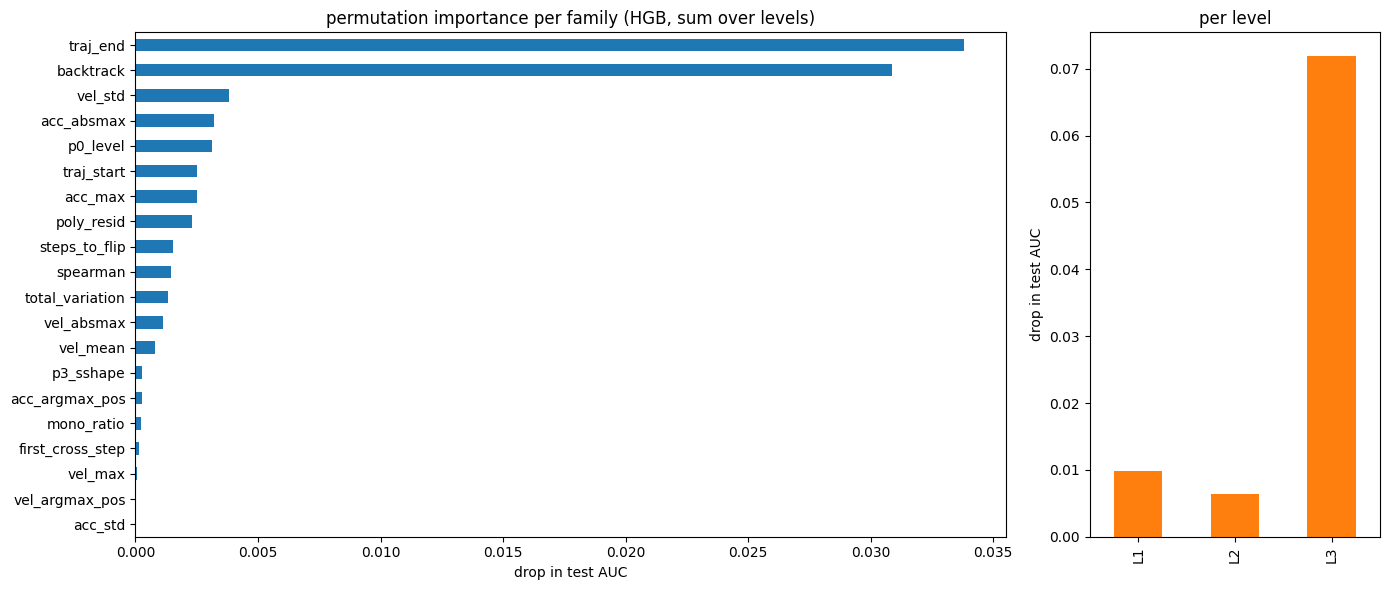

,perm importance
traj_end__L3,0.032441
backtrack__L3,0.030153
vel_std__L3,0.003406
p0_level__L1,0.002875
traj_start__L1,0.002106
acc_absmax__L2,0.002016
acc_max__L3,0.001720
steps_to_flip__L1,0.001554
spearman__L3,0.001305
backtrack__L2,0.001089


In [17]:
from sklearn.inspection import permutation_importance

X = X_all[FP_COLS].values.astype(float)
imp = []
for k in range(N_FOLDS):
    tr, te = folds != k, folds == k
    fit_kw = {"clf__groups": groups[tr]} if ABL_MODEL in NEEDS_GROUPS else {}
    m = make_model(ABL_MODEL).fit(X[tr], y[tr], **fit_kw)
    pi = permutation_importance(m, X[te], y[te], scoring="roc_auc", n_repeats=3,
                                random_state=RANDOM_SEED, n_jobs=1)
    imp.append(pi.importances_mean)
    print(f"fold {k} done", flush=True)
perm = pd.Series(np.mean(imp, 0), index=FP_COLS).sort_values(ascending=False)

fam = perm.groupby(perm.index.str.split("__").str[0]).sum().sort_values(ascending=False)
lvl = perm.groupby(perm.index.str.split("__").str[1]).sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [3, 1]})
fam.head(20)[::-1].plot.barh(ax=axes[0], color="C0")
axes[0].set_title(f"permutation importance per family ({ABL_MODEL}, sum over levels)")
axes[0].set_xlabel("drop in test AUC")
lvl.plot.bar(ax=axes[1], color="C1"); axes[1].set_title("per level"); axes[1].set_ylabel("drop in test AUC")
plt.tight_layout(); plt.show()
perm.head(15).to_frame("perm importance")

## 10. New trajectory features

The old features work in probability space, where the levels live on very different scales
(to_negative sits between 0.005 and 0.16). These are computed in **logit space**, relative to where the
trajectory was supposed to go, and signed so that positive always means "moved in the intended
direction". Per level:

| feature | what it measures |
|---|---|
| `jump0` | logit(first tracked step) - logit(orig_prob): how far the noising + first guided step already moved it |
| `early` | change over the first 3 tracked steps |
| `late` | change over the last 5 tracked steps (the tail rise seen in section 3) |
| `tgt_gap_mean`, `tgt_gap_end`, `tgt_gap_absmean` | distance to the level's soft target, signed (positive = still short of it) |
| `near_thr_frac` | fraction of steps within +-0.5 logit of the threshold |
| `far_side_frac` | fraction of steps on the target side of the threshold |

Across levels (one value per image): spread and ordering of the three endpoints, number of levels that
ended flipped, mean pairwise correlation of the three trajectories, and their mean pairwise distance.

In [18]:
def logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))

pred_all = img["orig_pred"].values
sign = np.where(pred_all == 1, -1.0, 1.0)[:, None]                  # (N, 1): intended direction
Lg = logit(P.astype(np.float64))                                    # (N, 3, S)
l_thr = logit(THR)
l_orig = logit(img["orig_prob"].values)
tgt = np.stack([np.array(lv[d]) for d in img["direction"]])         # (N, 3) soft targets
l_tgt = logit(tgt)

new_feats = {}
for li in range(3):
    L, s = Lg[:, li], sign
    gap = (l_tgt[:, li:li + 1] - L) * s
    crossed = (P[:, li] >= THR) != pred_all[:, None].astype(bool)
    new_feats.update({
        f"jump0__L{li + 1}":           (L[:, 0] - l_orig) * s[:, 0],
        f"early__L{li + 1}":           (L[:, 3] - L[:, 0]) * s[:, 0],
        f"late__L{li + 1}":            (L[:, -1] - L[:, -6]) * s[:, 0],
        f"tgt_gap_mean__L{li + 1}":    gap.mean(1),
        f"tgt_gap_end__L{li + 1}":     gap[:, -1],
        f"tgt_gap_absmean__L{li + 1}": np.abs(gap).mean(1),
        f"near_thr_frac__L{li + 1}":   (np.abs(L - l_thr) < 0.5).mean(1),
        f"far_side_frac__L{li + 1}":   crossed.mean(1),
    })

ends = Lg[:, :, -1] * sign                                          # (N, 3), signed endpoints
pairs = [(0, 1), (0, 2), (1, 2)]
def row_corr(a, b):
    a = a - a.mean(1, keepdims=True); b = b - b.mean(1, keepdims=True)
    den = np.sqrt((a ** 2).sum(1) * (b ** 2).sum(1))
    return np.where(den > 0, (a * b).sum(1) / np.where(den > 0, den, 1), np.nan)

new_feats.update({
    "x_end_spread":    ends.max(1) - ends.min(1),
    "x_end_ordered":   ((ends[:, 1] > ends[:, 0]) & (ends[:, 2] > ends[:, 1])).astype(float),
    "x_n_flipped":     ((P[:, :, -1] >= THR) != pred_all[:, None].astype(bool)).sum(1).astype(float),
    "x_traj_corr":     np.nanmean([row_corr(Lg[:, i], Lg[:, j]) for i, j in pairs], 0),
    "x_traj_dist":     np.mean([np.abs(Lg[:, i] - Lg[:, j]).mean(1) for i, j in pairs], 0),
})

NEW = pd.DataFrame(new_feats, index=img.index)
NEW = NEW.loc[:, NEW.nunique(dropna=False) > 1]
NEW_COLS = list(NEW.columns)
X_all = X_all.drop(columns=[c for c in NEW_COLS if c in X_all], errors="ignore").join(NEW)
print(f"{len(NEW_COLS)} new columns")

uni_new = pd.Series({c: uni_auc(X_all[c].values.astype(float)) for c in NEW_COLS}).sort_values(ascending=False)
uni_new.head(15).to_frame("univariate AUC")

28 new columns


,univariate AUC
tgt_gap_mean__L3,0.824792
tgt_gap_absmean__L3,0.824436
jump0__L3,0.818032
jump0__L2,0.806622
x_end_spread,0.806075
near_thr_frac__L2,0.805225
tgt_gap_end__L3,0.799052
late__L1,0.789214
tgt_gap_end__L1,0.787269
x_traj_dist,0.765870


In [19]:
newsets = {
    "new":                      NEW_COLS,
    "new +prob":                ["orig_prob"] + NEW_COLS,
    "fingerprint + new":        FP_COLS + NEW_COLS,
    "fingerprint + new +prob":  ["orig_prob"] + FP_COLS + NEW_COLS,
    "fingerprint +prob":        ["orig_prob"] + FP_COLS,
    "prob_only":                ["orig_prob"],
}
new_res = pd.DataFrame([row(n, c, cv_aucs(c)) for n, c in newsets.items()]).sort_values("mean_auc", ascending=False)
print(f"MSP: {MSP_AUC.mean():.4f}")
new_res

MSP: 0.8644


,set,n_cols,mean_auc,std_auc,vs_MSP,folds_beating_MSP,within_bin,within_vs_MSP
5,prob_only,1,0.861548,0.009356,-0.002885,1,0.522412,-0.008361
4,fingerprint +prob,97,0.860441,0.007757,-0.003992,1,0.517736,-0.013038
1,new +prob,29,0.860120,0.008134,-0.004313,0,0.516606,-0.014168
2,fingerprint + new,124,0.859309,0.009849,-0.005124,0,0.519285,-0.011489
3,fingerprint + new +prob,125,0.858947,0.008675,-0.005487,0,0.520198,-0.010575
0,new,28,0.858598,0.010158,-0.005835,0,0.515203,-0.015570


## 11. Features measured relative to the starting confidence

Section 9 showed the strong prob-space features (total variation, jitter) are mostly MSP again: a wobble
of fixed size in logit looks bigger in probability the closer the image sits to 0.5. Everything here is
built from the **signed logit displacement from the original**, `gain = (logit(p_t) - logit(orig_prob)) * sign`,
so it describes how C0 *responded*, not where it started.

**a. Effort.** `l1` from the manifest is the mean |CF - x0| per level. Caveat: it is almost the same at all
three levels (~0.034, the noise-and-denoise reconstruction change dominates), so
- `l1_recon` (the low level's l1) is mostly *how much the diffusion model alters this image at all*, a
  typicality signal in its own right
- `l1_extra` = l1(high) - l1(low) is the extra change the stronger push cost, and `eff_extra` is the extra
  logit bought per unit of it
- `eff_per_l1__L*` = end gain / l1, per level

**b. Spring-back.** `springback__L*` = (peak gain - end gain) / peak gain: the share of the best
displacement lost by the end, when guidance fades and C0 drifts back. `peak_gain__L*`, `peak_pos__L*`
(where along the run the peak sits).

**c. Response across levels.** Requested displacement `dx = (logit(target) - logit(orig)) * sign` against
achieved `dy = end gain`, over the three levels: `dose_slope`, `dose_resid` (rms misfit), `dose_inc_ratio`
(high-mid increment over mid-low increment: <1 means saturating), `dose_frac_high` (share of the
strongest request actually delivered).

In [20]:
S = P.shape[2]
gain = (Lg - l_orig[:, None, None]) * sign[:, :, None]           # (N, 3, S) signed logit displacement
end_gain, peak = gain[:, :, -1], gain.max(2)

l1 = man.pivot_table(index="path", columns="level", values="l1").loc[img.index, [1, 2, 3]].values

rel = {}
for li in range(3):
    L = f"__L{li + 1}"
    rel[f"eff_per_l1{L}"] = end_gain[:, li] / l1[:, li]
    rel[f"springback{L}"] = np.where(peak[:, li] > 0.1, (peak[:, li] - end_gain[:, li]) / np.maximum(peak[:, li], 1e-9), np.nan)
    rel[f"peak_gain{L}"]  = peak[:, li]
    rel[f"peak_pos{L}"]   = gain[:, li].argmax(1) / (S - 1)

l1_extra = l1[:, 2] - l1[:, 0]
rel["l1_recon"]  = l1[:, 0]
rel["l1_extra"]  = l1_extra
rel["eff_extra"] = np.where(np.abs(l1_extra) > 1e-5, (end_gain[:, 2] - end_gain[:, 0]) / np.where(np.abs(l1_extra) > 1e-5, l1_extra, 1), np.nan)

dx = (l_tgt - l_orig[:, None]) * sign                            # (N, 3) requested
dy = end_gain                                                    # (N, 3) achieved
dxc, dyc = dx - dx.mean(1, keepdims=True), dy - dy.mean(1, keepdims=True)
slope = (dxc * dyc).sum(1) / np.maximum((dxc ** 2).sum(1), 1e-9)
inc_lo, inc_hi = dy[:, 1] - dy[:, 0], dy[:, 2] - dy[:, 1]
rel["dose_slope"]     = slope
rel["dose_resid"]     = np.sqrt(((dyc - slope[:, None] * dxc) ** 2).mean(1))
rel["dose_inc_ratio"] = np.where(np.abs(inc_lo) > 0.05, inc_hi / np.where(np.abs(inc_lo) > 0.05, inc_lo, 1), np.nan)
rel["dose_frac_high"] = dy[:, 2] / np.where(np.abs(dx[:, 2]) > 1e-6, dx[:, 2], np.nan)

REL = pd.DataFrame(rel, index=img.index)
REL = REL.loc[:, REL.nunique(dropna=False) > 1]
REL_COLS = list(REL.columns)
X_all = X_all.drop(columns=[c for c in REL_COLS if c in X_all]).join(REL)

uni_rel = pd.DataFrame({
    "univariate AUC": {c: uni_auc(X_all[c].values.astype(float)) for c in REL_COLS},
    # within-bin, folded like the univariate AUC; NaN rows filled with the median just for this view
    "within-bin AUC": {c: (lambda a: max(a, 1 - a))(within_bin_auc(X_all[c].fillna(X_all[c].median()).values))
                       for c in REL_COLS},
}).sort_values("within-bin AUC", ascending=False)
print(f"{len(REL_COLS)} relative columns | reference within-bin: MSP {MSP_WITHIN:.4f}")
uni_rel

19 relative columns | reference within-bin: MSP 0.5308


,univariate AUC,within-bin AUC
springback__L3,0.534017,0.527898
springback__L2,0.685383,0.522442
dose_frac_high,0.800140,0.520860
peak_gain__L1,0.645896,0.519771
peak_gain__L2,0.737430,0.519709
peak_gain__L3,0.678633,0.518583
springback__L1,0.741602,0.515249
eff_per_l1__L1,0.525632,0.513787
eff_per_l1__L2,0.605378,0.513043
dose_slope,0.831159,0.512430


In [21]:
relsets = {
    "rel":                        REL_COLS,
    "rel +prob":                  ["orig_prob"] + REL_COLS,
    "rel + new +prob":            ["orig_prob"] + REL_COLS + NEW_COLS,
    "fingerprint + new + rel +prob": ["orig_prob"] + FP_COLS + NEW_COLS + REL_COLS,
    "fingerprint +prob":          ["orig_prob"] + FP_COLS,
    "prob_only":                  ["orig_prob"],
}
rel_res = pd.DataFrame([row(n, c, cv_aucs(c)) for n, c in relsets.items()]).sort_values("mean_auc", ascending=False)
rel_res

,set,n_cols,mean_auc,std_auc,vs_MSP,folds_beating_MSP,within_bin,within_vs_MSP
5,prob_only,1,0.861548,0.009356,-0.002885,1,0.522412,-0.008361
1,rel +prob,20,0.860867,0.008033,-0.003567,0,0.527466,-0.003308
4,fingerprint +prob,97,0.860441,0.007757,-0.003992,1,0.517736,-0.013038
2,rel + new +prob,48,0.859536,0.009193,-0.004898,0,0.510984,-0.019789
3,fingerprint + new + rel +prob,144,0.859371,0.009585,-0.005062,0,0.518306,-0.012467
0,rel,19,0.858535,0.008669,-0.005899,0,0.517519,-0.013255


## 12. One model per direction

`to_positive` (C0 said negative) and `to_negative` (C0 said positive) trajectories mean different
things, and the classes are very unbalanced between them (see the cell counts in section 1). Here each
direction gets its own model, trained on that direction's training rows only; the out-of-fold predictions
of the two are then pooled and scored exactly like everything else. The per-direction table underneath
shows where any gain comes from.

In [22]:
DIRECTION = img["direction"].values

def cv_aucs_bydir(cols, model_type=ABL_MODEL):
    X = X_all[cols].values.astype(float)
    aucs, oof = [], np.full(len(y), np.nan)
    for k in range(N_FOLDS):
        for d in np.unique(DIRECTION):
            tr = (folds != k) & (DIRECTION == d)
            te = (folds == k) & (DIRECTION == d)
            fit_kw = {"clf__groups": groups[tr]} if model_type in NEEDS_GROUPS else {}
            m = make_model(model_type).fit(X[tr], y[tr], **fit_kw)
            oof[te] = m.predict_proba(X[te])[:, 1]
        te = folds == k
        aucs.append(roc_auc_score(y[te], oof[te]))
    return np.array(aucs), oof

dirsets = {
    "prob_only":                  ["orig_prob"],
    "fingerprint +prob":          ["orig_prob"] + FP_COLS,
    "fingerprint + new + rel +prob": ["orig_prob"] + FP_COLS + NEW_COLS + REL_COLS,
}
dir_rows, dir_detail = [], []
for n, c in dirsets.items():
    for how, fn in (("pooled", cv_aucs), ("per-direction", cv_aucs_bydir)):
        r_ = fn(c)
        dir_rows.append({"how": how, **row(n, c, r_)})
        for d in np.unique(DIRECTION):
            m = DIRECTION == d
            dir_detail.append({"set": n, "how": how, "direction": d,
                               "auc": roc_auc_score(y[m], r_[1][m]),
                               "MSP auc": roc_auc_score(y[m], msp[m])})
pd.DataFrame(dir_rows).sort_values("mean_auc", ascending=False)

,how,set,n_cols,mean_auc,std_auc,vs_MSP,folds_beating_MSP,within_bin,within_vs_MSP
0,pooled,prob_only,1,0.861548,0.009356,-0.002885,1,0.522412,-0.008361
2,pooled,fingerprint +prob,97,0.860441,0.007757,-0.003992,1,0.517736,-0.013038
4,pooled,fingerprint + new + rel +prob,144,0.859371,0.009585,-0.005062,0,0.518306,-0.012467
1,per-direction,prob_only,1,0.855536,0.007893,-0.008898,0,0.515772,-0.015002
5,per-direction,fingerprint + new + rel +prob,144,0.852555,0.006550,-0.011878,0,0.520420,-0.010354
3,per-direction,fingerprint +prob,97,0.849750,0.007887,-0.014684,0,0.513625,-0.017149


In [23]:
pd.DataFrame(dir_detail).pivot_table(index=["set", "how"], columns="direction", values=["auc", "MSP auc"]).round(4)

MSP auc              \
direction                                   to_negative to_positive   
set                           how                                     
fingerprint + new + rel +prob per-direction      0.6084      0.6707   
                              pooled             0.6084      0.6707   
fingerprint +prob             per-direction      0.6084      0.6707   
                              pooled             0.6084      0.6707   
prob_only                     per-direction      0.6084      0.6707   
                              pooled             0.6084      0.6707   

                                                    auc              
direction                                   to_negative to_positive  
set                           how                                    
fingerprint + new + rel +prob per-direction      0.5733      0.6175  
                              pooled             0.5911      0.6525  
fingerprint +prob             per-direction      0.5572      0.6238  
                              pooled             0.5939      0.6570  
prob_only                     per-direction      0.5838      0.6212  
                              pooled             0.6008      0.6508

## 13. The raw trajectories

No hand-made features: the 3 x 30 signed logit displacements (`gain` above) go straight into the model.

- **HGB** on the 90 values as flat columns
- **1D CNN** (`SeqCNN`, section 5): two conv layers over the time axis with the three levels as channels,
  mean + max pooled, then a small head; any extra columns (`orig_prob`) join at the head. Trained like
  the MLP (class-balanced BCE, val-AUC early stopping on a patient-grouped 20% split). ~ a few minutes
  per set on CPU.

In [24]:
RAW = pd.DataFrame(gain.reshape(len(gain), -1), index=img.index,
                   columns=[f"raw_L{l + 1}_s{s:02d}" for l in range(3) for s in range(S)])
RAW_COLS = list(RAW.columns)                                     # level-major, which SeqCNN relies on
X_all = X_all.drop(columns=[c for c in RAW_COLS if c in X_all]).join(RAW)

raw_res = pd.DataFrame([
    {"model": "HGB", **row("raw",       RAW_COLS,                 cv_aucs(RAW_COLS, "HGB"))},
    {"model": "HGB", **row("raw +prob", RAW_COLS + ["orig_prob"], cv_aucs(RAW_COLS + ["orig_prob"], "HGB"))},
    {"model": "CNN", **row("raw",       RAW_COLS,                 cv_aucs(RAW_COLS, "CNN"))},
    {"model": "CNN", **row("raw +prob", RAW_COLS + ["orig_prob"], cv_aucs(RAW_COLS + ["orig_prob"], "CNN"))},
]).sort_values("mean_auc", ascending=False)
raw_res

,model,set,n_cols,mean_auc,std_auc,vs_MSP,folds_beating_MSP,within_bin,within_vs_MSP
2,CNN,raw,90,0.862901,0.008216,-0.001533,0,0.528900,-0.001874
3,CNN,raw +prob,91,0.862252,0.009413,-0.002181,0,0.522966,-0.007807
1,HGB,raw +prob,91,0.858341,0.009148,-0.006092,0,0.517991,-0.012782
0,HGB,raw,90,0.856148,0.010030,-0.008286,0,0.515021,-0.015752


## 14. K = 3 as an ensemble of per-level scores (the attribute arm's protocol)

Everything above puts the three trajectories **side by side** in one row. The attribute and CNN ladders
combine K counterfactuals differently (`c2_train_attributes.py`, "More than one counterfactual per
query"): **by ensembling scores, never features**.

- **train**: one row per image, built from slot 0 only. For the diffusion arm the slot order is
  high, mid, low, so slot 0 = **L3 (high)**
- **test**: the fitted model is applied once per level, and the K predicted probabilities are averaged

So the feature space is one trajectory wide at every K, and K=1 (high alone) is a strict prefix of K=3.
Only per-level features qualify: the old fingerprint, section 10's per-level features and section 11's
per-level features, each with the `__L<k>` suffix stripped so the three levels share one set of columns.
The cross-level ones (`x_*`, `dose_*`, `l1_recon`, `l1_extra`, `eff_extra`) need all three levels in one
row, so they are left out here.

`train on` = `high` is the faithful protocol. `all` is a variant: the same model fit on the three levels
stacked (3 rows per image, same label), so it has seen every level it is later applied to.

In [25]:
SLOT_ORDER = [3, 2, 1]                                           # high, mid, low -> slot 0, 1, 2

def families(cols):
    # feature families present at all three levels, e.g. "vel_mean" for vel_mean__L1..L3
    fam = {}
    for c in cols:
        if "__L" in c:
            f, l = c.rsplit("__L", 1)
            fam.setdefault(f, set()).add(int(l))
    return sorted(f for f, ls in fam.items() if ls == {1, 2, 3})

def slot_matrix(fams, level, with_prob):
    X = X_all[[f"{f}__L{level}" for f in fams]].values.astype(float)
    return np.column_stack([X_all["orig_prob"].values, X]) if with_prob else X

def cv_slots(fams, with_prob=True, model_type=ABL_MODEL, train_on="high"):
    # -> {K: (per-fold AUCs, OOF mean-of-K sigmoids)} for K = 1, 2, 3
    Xs = [slot_matrix(fams, l, with_prob) for l in SLOT_ORDER]
    per_slot = np.full((len(SLOT_ORDER), len(y)), np.nan)
    for k in range(N_FOLDS):
        tr, te = folds != k, folds == k
        if train_on == "high":
            X_tr, y_tr, g_tr = Xs[0][tr], y[tr], groups[tr]
        else:                                                    # "all": stack the three levels
            X_tr = np.vstack([X[tr] for X in Xs])
            y_tr, g_tr = np.tile(y[tr], 3), np.tile(groups[tr], 3)
        fit_kw = {"clf__groups": g_tr} if model_type in NEEDS_GROUPS else {}
        m = make_model(model_type).fit(X_tr, y_tr, **fit_kw)
        for j, X in enumerate(Xs):
            per_slot[j, te] = m.predict_proba(X[te])[:, 1]
    out = {}
    for K in (1, 2, 3):
        oof = per_slot[:K].mean(0)
        out[K] = (np.array([roc_auc_score(y[folds == k], oof[folds == k]) for k in range(N_FOLDS)]), oof)
    return out

fam_sets = {
    "fingerprint":             families(FP_COLS),
    "fingerprint + new + rel": families(FP_COLS + NEW_COLS + REL_COLS),
}
ens = []
for name, fams in fam_sets.items():
    for with_prob in (False, True):
        for train_on in ("high", "all"):
            res_k = cv_slots(fams, with_prob=with_prob, train_on=train_on)
            label = name + (" +prob" if with_prob else "")
            for K, r_ in res_k.items():
                ens.append({"train on": train_on, "K": K, **row(label, fams, r_)})
            print(f"{label:<32} train on {train_on:<4} done", flush=True)
ens = pd.DataFrame(ens)
ens.sort_values("mean_auc", ascending=False)

fingerprint                      train on high done
fingerprint                      train on all  done
fingerprint +prob                train on high done
fingerprint +prob                train on all  done
fingerprint + new + rel          train on high done
fingerprint + new + rel          train on all  done
fingerprint + new + rel +prob    train on high done
fingerprint + new + rel +prob    train on all  done


,train on,K,set,n_cols,mean_auc,std_auc,vs_MSP,folds_beating_MSP,within_bin,within_vs_MSP
11,all,3,fingerprint +prob,32,0.863444,0.008471,-0.000990,2,0.523650,-0.007123
10,all,2,fingerprint +prob,32,0.863220,0.008556,-0.001213,2,0.524487,-0.006286
23,all,3,fingerprint + new + rel +prob,44,0.863106,0.008767,-0.001327,1,0.521034,-0.009739
22,all,2,fingerprint + new + rel +prob,44,0.862800,0.008998,-0.001633,1,0.520351,-0.010423
9,all,1,fingerprint +prob,32,0.862439,0.008555,-0.001994,1,0.530379,-0.000394
21,all,1,fingerprint + new + rel +prob,44,0.862073,0.008704,-0.002361,1,0.526851,-0.003923
17,all,3,fingerprint + new + rel,44,0.861824,0.009340,-0.002609,0,0.518452,-0.012321
16,all,2,fingerprint + new + rel,44,0.861732,0.008737,-0.002701,1,0.520080,-0.010693
6,high,1,fingerprint +prob,32,0.860660,0.008921,-0.003773,0,0.531616,0.000842
15,all,1,fingerprint + new + rel,44,0.860642,0.008934,-0.003791,1,0.517991,-0.012782


In [26]:
# K=1 -> K=3 at a glance: does averaging the weaker levels help?
ens.pivot_table(index=["set", "train on"], columns="K", values=["mean_auc", "within_bin"]).round(4)

mean_auc                 within_bin  \
K                                             1       2       3          1   
set                           train on                                       
fingerprint                   all        0.8422  0.8439  0.8465     0.5145   
                              high       0.8385  0.8367  0.8370     0.5125   
fingerprint + new + rel       all        0.8606  0.8617  0.8618     0.5180   
                              high       0.8580  0.8546  0.8505     0.5177   
fingerprint + new + rel +prob all        0.8621  0.8628  0.8631     0.5269   
                              high       0.8600  0.8539  0.8493     0.5167   
fingerprint +prob             all        0.8624  0.8632  0.8634     0.5304   
                              high       0.8607  0.8568  0.8529     0.5316   

                                                        
K                                            2       3  
set                           train on                  
fingerprint                   all       0.5133  0.5164  
                              high      0.5029  0.5046  
fingerprint + new + rel       all       0.5201  0.5185  
                              high      0.5114  0.5095  
fingerprint + new + rel +prob all       0.5204  0.5210  
                              high      0.5091  0.5111  
fingerprint +prob             all       0.5245  0.5237  
                              high      0.5128  0.5100

## Next

- rerun the promising sets with `ABL_MODEL = "MLP"`
- the band near the threshold: AUC restricted to images with `orig_prob` close to C0's threshold
- the other diseases (`DISEASE` at the top; atelectasis and consolidation have folds)